# 05 · Evaluación e interpretación del modelo

**Ciencia de Datos Aplicada (ITBA) · Cuarto entregable: despliegue y presentación de la solución**

**Equipo:** Juan Ignacio Fernández Dinardo, Gianfranco Magliotti, Santiago Joaquín Nartallo Galvagno

**Proyecto:** Modelo predictivo de demanda de Ecobici (CABA)

**Qué hace este notebook:** mide para qué sirve el modelo que está desplegado y explica cómo decide. **No reentrena nada:** usa los modelos guardados en `models/`, los mismos que sirve la API, y el período de test del notebook 04 (junio a agosto de 2026).

**Entrada:** `models/`, `data/processed/` (notebook 03), `data/interim/viajes.parquet` (notebook 01) y las fotos crudas de `datasets/archive/`.

## Correcciones aplicadas en base al feedback de la tercera entrega

| Devolución | Qué se hizo | Dónde | Resultado |
|---|---|---|---|
| *"¿Cuántas estaciones vacías o llenas se habrían evitado en el período de test usando las predicciones del modelo frente al baseline de la media histórica?"* | Simulación del rebalanceo en 106 franjas pico del test, con los viajes reales y las mismas bicis para mover en cada política | 1 | Con 100 bicis por franja, el modelo **evita el 52 % de las alertas** y la media histórica el 49 %: quedan un **4,8 % menos de alertas** (IC 95 %: 3,9 a 5,8). En usuarios sin bici o sin anclaje empatan |
| *"desglosar el error por clusters o zonas geográficas"* | WAPE por grupo de K-means, zona, tipo de día y franja, comparado con el piso que impone el azar | 2 | El error **casi no cambia entre zonas** (28 a 32 %). Cambia con el **tipo de día**: 26 % en días hábiles y 46 % en no hábiles. Lo más difícil de predecir son las estaciones recreativas |
| *"incorporar valores SHAP (...) visualizar interacciones complejas no lineales"* | SHAP sobre el boosting: importancia global, lluvia × hora, temperatura × nivel y tipo de día, y un ejemplo | 3 | La lluvia baja la demanda del 22 % (llovizna) al 60 % (fuerte), y **algo más a la mañana**. La temperatura tiene forma de U invertida, **más marcada los fines de semana**. El efecto relativo casi no depende del nivel de la estación |

## 0. Configuración

In [1]:
from pathlib import Path
import json
import time
import warnings

import duckdb
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import poisson

warnings.filterwarnings("ignore", message=".*'generic' unit for NumPy timedelta.*")  # aviso interno de pandas con numpy 2
warnings.filterwarnings("ignore", message="X does not have valid feature names")  # shap predice con una matriz
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

REPO_DIR = Path("..").resolve()
DATASET = REPO_DIR / "data" / "processed" / "dataset_estacion_hora.parquet"
VIAJES = REPO_DIR / "data" / "interim" / "viajes.parquet"
MODELS_DIR = REPO_DIR / "models"
FOTOS_CRUDAS = REPO_DIR / "datasets" / "archive" / "stations" / "buenos-aires" / "ecobici"

ZONA_HORARIA = "America/Argentina/Buenos_Aires"
TEST_DESDE, TEST_HASTA = pd.Timestamp("2026-06-01"), pd.Timestamp("2026-09-01")
SEMILLA = 42

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8c86"
AZULES = LinearSegmentedColormap.from_list("azules", ["#e3eefb", BLUE, "#123a6b"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "axes.axisbelow": True})

for ruta in (DATASET, VIAJES, MODELS_DIR / "metadata.json", FOTOS_CRUDAS):
    assert ruta.exists(), f"No se encontró {ruta} (ver el README)."

meta = json.loads((MODELS_DIR / "metadata.json").read_text(encoding="utf-8"))
VARIABLES = meta["variables"]
modelo_retiros = joblib.load(MODELS_DIR / "hgb_retiros.joblib")
modelo_arribos = joblib.load(MODELS_DIR / "hgb_arribos.joblib")
estaciones = (pd.read_csv(REPO_DIR / "data" / "processed" / "estaciones.csv", index_col="station_id")
                .join(pd.read_csv(MODELS_DIR / "grupos_estaciones.csv", index_col="station_id").nombre_grupo))

con = duckdb.connect()
con.execute("SET enable_progress_bar = false")
con.execute(f"SET TimeZone = '{ZONA_HORARIA}'")
print(f"Modelo entrenado el {meta['entrenado'][:10]} con datos hasta el {meta['periodo_entrenamiento'][1][:10]} · shap {shap.__version__}")

Modelo entrenado el 2026-11-03 con datos hasta el 2026-05-31 · shap 0.54.1


**Predicciones del test.** Las variables se arman con la consulta guardada en `metadata.json`, la misma del entrenamiento. La **media histórica** (estación × hora × tipo de día, calculada sólo con el train) es el baseline recomendado en el notebook 04. Como control, el WAPE diario tiene que dar lo mismo que en el notebook 04.

In [2]:
def variables(desde, hasta):
    # 29 días de margen: la ventana más larga de la consulta mira 28 días antes del día anterior
    consulta = meta["consulta_variables"].format(fuente=DATASET.as_posix(), desde=f"{desde - pd.Timedelta(days=29):%Y-%m-%d}")
    return con.execute(f"SELECT * FROM ({consulta}) WHERE ts >= ? AND ts < ? ORDER BY station_id, ts",
                       [desde.to_pydatetime(), hasta.to_pydatetime()]).df()


test = variables(TEST_DESDE, TEST_HASTA)
test["pred_retiros"] = modelo_retiros.predict(test[VARIABLES])
test["pred_arribos"] = modelo_arribos.predict(test[VARIABLES])

media = con.execute(f"""
    SELECT station_id, hora, dia_habil, avg(retiros) AS base_retiros, avg(arribos) AS base_arribos
    FROM read_parquet('{DATASET.as_posix()}') WHERE split = 'train' GROUP BY ALL
""").df()
global_train = con.execute(f"SELECT avg(retiros), avg(arribos) FROM read_parquet('{DATASET.as_posix()}') WHERE split = 'train'").fetchone()
test = test.merge(media, on=["station_id", "hora", "dia_habil"], how="left", validate="many_to_one")
test["base_retiros"] = test.base_retiros.fillna(global_train[0])
test["base_arribos"] = test.base_arribos.fillna(global_train[1])
test["fecha"] = test.ts.dt.floor("D")

diario = test.groupby(["station_id", "fecha", "dia_habil"], as_index=False)[["retiros", "pred_retiros", "base_retiros"]].sum()


def wape(real, pred):
    return 100 * (pred - real).abs().sum() / real.sum()


wape_modelo, wape_media = wape(diario.retiros, diario.pred_retiros), wape(diario.retiros, diario.base_retiros)
assert round(wape_modelo, 1) == round(meta["metricas_test"]["retiros"]["WAPE diario %"], 1)
print(f"{len(test):,} filas · WAPE diario: modelo {wape_modelo:.1f} %, media histórica {wape_media:.1f} %")

870,753 filas · WAPE diario: modelo 29.0 %, media histórica 52.1 %


## 1. Impacto operativo: ¿cuántas estaciones vacías o llenas se evitan?

**Devolución:** *"¿Cuántas estaciones vacías o llenas se habrían evitado en el período de test usando las predicciones del modelo frente al baseline de la media histórica?"*

### 1.1 Cómo se simula

Para cada **día hábil** del test y cada **franja pico** (6 a 10 h y 16 a 20 h, las mismas de la API):

1. **Stock inicial.** La última foto de la red antes de la franja (hasta 2 h antes), actualizada con los viajes entre la foto y el inicio. La capacidad de cada estación es bicis disponibles + anclajes libres.
2. **Plan.** Con un presupuesto de *B* bicis para mover, se decide de qué estación a qué estación va cada una. Para eso se calcula, con el pronóstico de cada política, **cuánto tiempo esperamos que cada estación pase vacía o llena según el stock con el que arranca** (un proceso de nacimiento y muerte con las tasas de retiros y arribos de cada hora, en pasos de 2 minutos). Después se mueve de a una bici, desde donde menos se pierde hacia donde más se gana.
3. **Qué habría pasado.** Se repiten los **viajes reales** de la franja, en orden, partiendo del stock que dejó el plan. Si un retiro llega con la estación vacía, ese usuario se queda sin bici. Si un arribo llega con la estación llena, se queda sin anclaje.

| Política | Con qué decide |
|---|---|
| Sin mover | No hace nada |
| Equilibrar el stock | No usa pronóstico: lleva bicis de la estación más llena a la más vacía (en proporción) |
| Media histórica | El plan de arriba, con la media histórica |
| **Modelo** | El plan de arriba, con el gradient boosting |
| Demanda conocida | El plan de arriba, con los viajes reales de cada hora. Es una **referencia de máximo**, imposible en la práctica |

Todas mueven la **misma cantidad de bicis** y se evalúan con los mismos viajes, así que la diferencia entre el modelo y la media histórica sale sólo del pronóstico.

**Qué se mide:** una **alerta** es una estación que en algún momento de la franja está vacía o llena. También se informan las horas-estación en alerta y los usuarios sin bici o sin anclaje.

In [3]:
FRANJAS = {"mañana": 6, "tarde": 16}
HORAS_FRANJA, MINUTOS = 4, 240
MAX_ANTIGUEDAD = pd.Timedelta(hours=2)

con.execute(f"""
CREATE OR REPLACE TABLE fotos AS
SELECT TRY_CAST(station_id AS INTEGER) AS station_id,
       CAST(committed_at_utc AT TIME ZONE '{ZONA_HORARIA}' AS TIMESTAMP) AS ts,
       num_bikes_available AS bicis, num_docks_available AS anclajes, is_renting AND is_returning AS abierta
FROM read_parquet('{(FOTOS_CRUDAS / "*" / "*.parquet").as_posix()}', union_by_name = true)
WHERE capacity > 0 AND committed_at_utc >= TIMESTAMPTZ '2026-05-31 00:00:00-03'
  AND committed_at_utc < TIMESTAMPTZ '2026-09-01 00:00:00-03'
QUALIFY row_number() OVER (PARTITION BY station_id, committed_at_utc ORDER BY num_bikes_available, num_docks_available) = 1
""")
# mismas reglas de limpieza del notebook 03
eventos = con.execute(f"""
WITH viajes AS (
    SELECT DISTINCT ON (id_recorrido) * FROM read_parquet('{VIAJES.as_posix()}')
    WHERE fecha_origen >= '2026-05-31' AND fecha_origen < '2026-09-01' AND duracion_seg BETWEEN 61 AND 86400
      AND NOT (id_estacion_origen = id_estacion_destino AND duracion_seg < 120))
SELECT id_estacion_origen AS station_id, fecha_origen AS ts, -1 AS cambio FROM viajes
UNION ALL
SELECT id_estacion_destino, fecha_destino, 1 FROM viajes
ORDER BY ts, station_id, cambio
""").df()
eventos_por_dia = dict(list(eventos.groupby(eventos.ts.dt.floor("D"))))

TASAS = {"Modelo": ("pred_retiros", "pred_arribos"), "Media histórica": ("base_retiros", "base_arribos"),
         "Demanda conocida": ("retiros", "arribos")}
casos = []
dias_habiles = sorted(test.loc[test.dia_habil == 1, "fecha"].unique())
for dia in dias_habiles:
    for franja, hora in FRANJAS.items():
        inicio = dia + pd.Timedelta(hours=hora)
        fin = inicio + pd.Timedelta(hours=HORAS_FRANJA)
        foto = con.execute("SELECT * FROM fotos WHERE ts = (SELECT max(ts) FROM fotos WHERE ts <= ?) ORDER BY station_id", [inicio.to_pydatetime()]).df()
        if inicio - foto.ts.max() > MAX_ANTIGUEDAD:
            continue
        grilla = test[(test.ts >= inicio) & (test.ts < fin)]
        foto = foto[foto.abierta & (foto.bicis + foto.anclajes > 0) & foto.station_id.isin(grilla.station_id)].set_index("station_id")
        movimientos = eventos_por_dia[dia]
        previos = movimientos[(movimientos.ts > foto.ts.iloc[0]) & (movimientos.ts < inicio)].groupby("station_id").cambio.sum()
        capacidad = (foto.bicis + foto.anclajes).to_numpy(int)
        stock = np.clip(foto.bicis.add(previos.reindex(foto.index).fillna(0)).to_numpy(int), 0, capacidad)

        franja_mov = movimientos[(movimientos.ts >= inicio) & (movimientos.ts < fin)]
        secuencias = {e: (g.cambio.to_numpy(), ((g.ts - inicio).dt.total_seconds() / 60).to_numpy())
                      for e, g in franja_mov.groupby("station_id")}
        casos.append({
            "fecha": dia, "franja": franja, "inicio": inicio, "estaciones": foto.index.to_numpy(), "stock": stock, "capacidad": capacidad,
            "secuencias": [secuencias.get(e, (np.array([], int), np.array([]))) for e in foto.index],
            "tasas": {p: [grilla.pivot(index="station_id", columns="hora", values=c).reindex(foto.index).fillna(0).to_numpy(float)
                          for c in columnas] for p, columnas in TASAS.items()}})

print(f"{len(casos)} franjas con stock inicial conocido de {len(dias_habiles) * len(FRANJAS)}: "
      + ", ".join(f"{n} de {f}" for f, n in pd.Series([c['franja'] for c in casos]).value_counts().items()))
print(f"Por franja, en promedio: {np.mean([len(c['estaciones']) for c in casos]):.0f} estaciones, "
      f"{np.mean([c['stock'].sum() for c in casos]):.0f} bicis disponibles, "
      f"{100 * np.mean([(c['stock'] == 0).mean() for c in casos]):.1f} % de las estaciones arrancan vacías")

106 franjas con stock inicial conocido de 124: 56 de tarde, 50 de mañana
Por franja, en promedio: 393 estaciones, 2177 bicis disponibles, 12.9 % de las estaciones arrancan vacías


In [4]:
PASO = 1 / 30  # 2 minutos, en horas


def costo_esperado(retiros, arribos, capacidad, objetivo):
    """Matriz estación × stock inicial: costo esperado en la franja si arranca con ese stock."""
    niveles = np.arange(capacidad.max() + 1)
    vacia, llena = (niveles == 0)[None, :], niveles[None, :] == capacidad[:, None]
    costo = np.zeros((len(capacidad), len(niveles)))
    pasos_por_hora = round(1 / PASO)
    for paso in range(HORAS_FRANJA * pasos_por_hora - 1, -1, -1):
        p_ret = retiros[:, [paso // pasos_por_hora]] * PASO
        p_arr = arribos[:, [paso // pasos_por_hora]] * PASO
        baja = np.hstack([costo[:, :1], costo[:, :-1]])
        sube = np.where(llena, costo, np.hstack([costo[:, 1:], costo[:, -1:]]))
        siguiente = p_ret * baja + p_arr * sube + (1 - p_ret - p_arr) * costo
        costo = siguiente + (PASO * (vacia | llena) if objetivo == "tiempo" else p_ret * vacia + p_arr * llena)
    costo[niveles[None, :] > capacidad[:, None]] = np.nan
    return costo


def plan_con_pronostico(costo, stock, capacidad, presupuestos):
    stock, filas, planes = stock.copy(), np.arange(len(stock)), {}
    borde = np.pad(costo, ((0, 0), (1, 1)), constant_values=np.nan)
    for movidas in range(1, max(presupuestos) + 1):
        actual = borde[filas, stock + 1]
        ganancia = np.where(stock < capacidad, actual - borde[filas, stock + 2], -np.inf)  # agregar una bici
        perdida = np.where(stock > 0, borde[filas, stock] - actual, np.inf)                 # sacar una bici
        destino, origen = np.nanargmax(ganancia), np.nanargmin(perdida)
        if destino != origen and ganancia[destino] - perdida[origen] > 1e-3:
            stock[destino] += 1
            stock[origen] -= 1
        if movidas in presupuestos:
            planes[movidas] = stock.copy()
    return planes


def plan_equilibrar(stock, capacidad, presupuestos):
    stock, planes = stock.copy(), {}
    for movidas in range(1, max(presupuestos) + 1):
        ocupacion = stock / capacidad
        destino = np.where(stock < capacidad, ocupacion, np.inf).argmin()
        origen = np.where(stock > 0, ocupacion, -np.inf).argmax()
        if ocupacion[origen] - ocupacion[destino] > 0.2:
            stock[destino] += 1
            stock[origen] -= 1
        if movidas in presupuestos:
            planes[movidas] = stock.copy()
    return planes


def repetir_viajes(secuencia, stock, capacidad):
    """Repite los viajes reales: usuarios sin bici, sin anclaje, si se vació, si se llenó, minutos vacía y minutos llena."""
    sin_bici = sin_anclaje = 0
    vacia, llena = stock == 0, stock == capacidad
    min_vacia = min_llena = anterior = 0.0
    for cambio, minuto in zip(*secuencia):
        min_vacia += (minuto - anterior) * (stock == 0)
        min_llena += (minuto - anterior) * (stock == capacidad)
        anterior = minuto
        if cambio < 0:
            sin_bici += stock == 0
            stock -= stock > 0
        else:
            sin_anclaje += stock == capacidad
            stock += stock < capacidad
        vacia |= stock == 0
        llena |= stock == capacidad
    min_vacia += (MINUTOS - anterior) * (stock == 0)
    min_llena += (MINUTOS - anterior) * (stock == capacidad)
    return np.array([sin_bici, sin_anclaje, vacia, llena, min_vacia, min_llena], float)


# Control: en una estación con 2 bicis y 2 anclajes, tres retiros seguidos dejan a un usuario sin bici
control = repetir_viajes((np.array([-1, -1, -1]), np.array([0.0, 10.0, 20.0])), 2, 4)
assert control.tolist() == [1, 0, 1, 0, 230, 0]

**¿La simulación reproduce la realidad?** Antes de usarla se compara el stock simulado **sin mover nada** con las fotos tomadas **durante** la franja, que la simulación no usa. Las diferencias son, sobre todo, movimientos que no son viajes: el rebalanceo real del operador y las bicis que se rompen o se reparan.

In [5]:
comparacion = []
for caso in casos:
    fotos_franja = con.execute("SELECT station_id, ts, bicis FROM fotos WHERE ts > ? AND ts <= ?",
                               [caso["inicio"].to_pydatetime(), (caso["inicio"] + pd.Timedelta(minutes=MINUTOS)).to_pydatetime()]).df()
    posicion = {e: i for i, e in enumerate(caso["estaciones"])}
    fotos_franja = fotos_franja[fotos_franja.station_id.isin(posicion)]
    for foto in fotos_franja.itertuples():
        i = posicion[foto.station_id]
        cambios, minutos = caso["secuencias"][i]
        stock, minuto_foto = caso["stock"][i], (foto.ts - caso["inicio"]).total_seconds() / 60
        for cambio in cambios[minutos <= minuto_foto]:
            stock = min(max(stock + cambio, 0), caso["capacidad"][i])
        comparacion.append((stock, caso["stock"][i], foto.bicis))
comparacion = pd.DataFrame(comparacion, columns=["simulado", "inicial", "observado"])
pd.DataFrame({
    "simulación sin mover": [comparacion.simulado.corr(comparacion.observado), (comparacion.simulado - comparacion.observado).abs().mean(),
                             100 * ((comparacion.simulado == 0) == (comparacion.observado == 0)).mean()],
    "suponer que el stock no cambia": [comparacion.inicial.corr(comparacion.observado), (comparacion.inicial - comparacion.observado).abs().mean(),
                                       100 * ((comparacion.inicial == 0) == (comparacion.observado == 0)).mean()],
}, index=["correlación con el stock observado", "error absoluto medio (bicis)", "% que coincide en si está vacía"]).round(2)

,simulación sin mover,suponer que el stock no cambia
correlación con el stock observado,0.98,0.87
error absoluto medio (bicis),0.44,1.61
% que coincide en si está vacía,95.79,86.32


### 1.2 Resultados

In [6]:
PRESUPUESTOS = [25, 50, 100, 200, 400]
METRICAS = ["sin bici", "sin anclaje", "se vacían", "se llenan", "min vacía", "min llena"]
OBJETIVOS = {"tiempo": "minimizar el tiempo vacía o llena", "usuarios": "minimizar los usuarios sin bici o sin anclaje"}


def simular():
    filas = []
    for caso in casos:
        memoria = {}

        def resultado(stock):
            total = np.zeros(len(METRICAS))
            for i, bicis in enumerate(stock):
                if (i, bicis) not in memoria:
                    memoria[i, bicis] = repetir_viajes(caso["secuencias"][i], bicis, caso["capacidad"][i])
                total += memoria[i, bicis]
            return total

        planes = {("-", "Sin mover", 0): caso["stock"]}
        planes |= {("-", "Equilibrar el stock", b): s for b, s in plan_equilibrar(caso["stock"], caso["capacidad"], PRESUPUESTOS).items()}
        for objetivo in OBJETIVOS:
            for politica, (retiros, arribos) in caso["tasas"].items():
                costo = costo_esperado(retiros, arribos, caso["capacidad"], objetivo)
                planes |= {(objetivo, politica, b): s
                           for b, s in plan_con_pronostico(costo, caso["stock"], caso["capacidad"], PRESUPUESTOS).items()}
        for (objetivo, politica, presupuesto), stock in planes.items():
            assert stock.sum() == caso["stock"].sum()  # las bicis no se crean ni se pierden
            filas.append([caso["fecha"], caso["franja"], objetivo, politica, presupuesto,
                          np.abs(stock - caso["stock"]).sum() / 2, *resultado(stock)])
    return pd.DataFrame(filas, columns=["fecha", "franja", "objetivo", "política", "B", "movidas", *METRICAS])


inicio = time.perf_counter()
simulacion = simular()
simulacion["alertas"] = simulacion["se vacían"] + simulacion["se llenan"]
simulacion["horas en alerta"] = (simulacion["min vacía"] + simulacion["min llena"]) / 60
simulacion["usuarios afectados"] = simulacion["sin bici"] + simulacion["sin anclaje"]
print(f"Simulación: {time.perf_counter() - inicio:.0f} s")

RESUMEN = ["movidas", "se vacían", "se llenan", "alertas", "horas en alerta", "usuarios afectados"]
orden_politicas = ["Sin mover", "Equilibrar el stock", "Media histórica", "Modelo", "Demanda conocida"]


def tabla(objetivo, presupuesto):
    elegidas = simulacion[(simulacion.B.isin([0, presupuesto])) & simulacion.objetivo.isin(["-", objetivo])]
    t = elegidas.groupby("política")[RESUMEN].mean().loc[orden_politicas]
    t["alertas evitadas %"] = 100 * (1 - t.alertas / t.loc["Sin mover", "alertas"])
    t["usuarios afectados evitados %"] = 100 * (1 - t["usuarios afectados"] / t.loc["Sin mover", "usuarios afectados"])
    return t.round(1)


print("Promedio por franja, con 100 bicis para mover")
pd.concat({OBJETIVOS[o]: tabla(o, 100) for o in OBJETIVOS}, names=["el plan busca", "política"])

Simulación: 11 s
Promedio por franja, con 100 bicis para mover


movidas  se vacían  se llenan  alertas  horas en alerta  usuarios afectados  alertas evitadas %  usuarios afectados evitados %
el plan busca                                 política                                                                                                                                           
minimizar el tiempo vacía o llena             Sin mover                0.0      123.5       29.5    153.0            240.5                27.7                 0.0                            0.0
                                              Equilibrar el stock     98.5       63.7        8.1     71.9             79.0                19.8                53.0                           28.7
                                              Media histórica        100.0       70.5        7.2     77.7             86.1                20.6                49.2                           25.9
                                              Modelo                 100.0       67.0        7.0     74.0             79.4                20.5                51.6                           25.9
                                              Demanda conocida        98.1       54.6        3.8     58.3             49.7                16.4                61.9                           40.7
minimizar los usuarios sin bici o sin anclaje Sin mover                0.0      123.5       29.5    153.0            240.5                27.7                 0.0                            0.0
                                              Equilibrar el stock     98.5       63.7        8.1     71.9             79.0                19.8                53.0                           28.7
                                              Media histórica        100.0       72.9        7.4     80.3             98.2                18.3                47.5                           34.1
                                              Modelo                 100.0       68.1        6.8     74.9             88.4                18.5                51.0                           33.4
                                              Demanda conocida        98.1       67.3        7.4     74.7            116.5                 2.5                51.2                           90.8

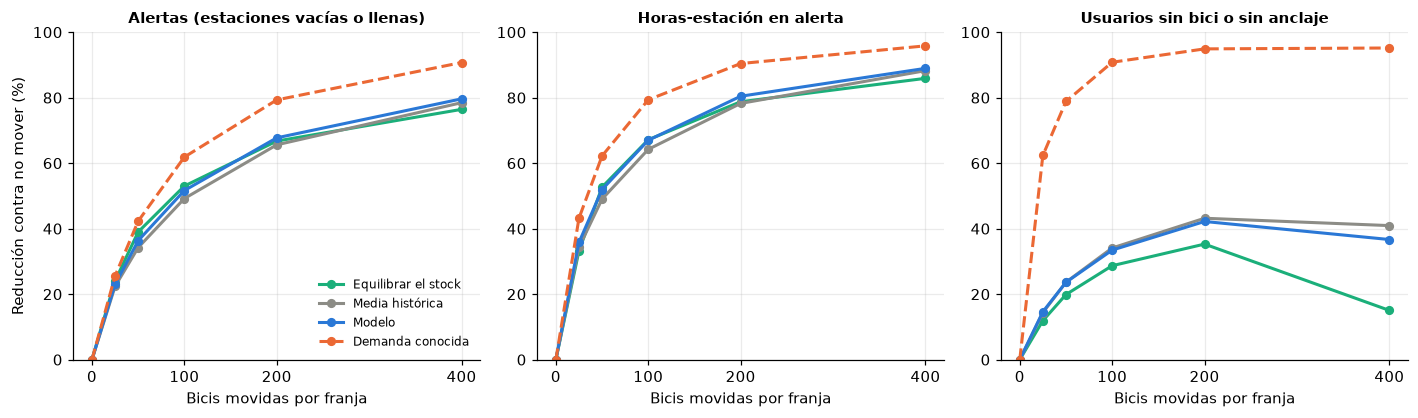

In [7]:
COLOR_POLITICA = {"Equilibrar el stock": AQUA, "Media histórica": GRAY, "Modelo": BLUE, "Demanda conocida": ORANGE}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
paneles = [("tiempo", "alertas", "Alertas (estaciones vacías o llenas)"), ("tiempo", "horas en alerta", "Horas-estación en alerta"),
           ("usuarios", "usuarios afectados", "Usuarios sin bici o sin anclaje")]
for ax, (objetivo, metrica, titulo) in zip(axes, paneles):
    base = simulacion[simulacion.B == 0][metrica].mean()
    for politica, color in COLOR_POLITICA.items():
        curva = simulacion[(simulacion["política"] == politica) & simulacion.objetivo.isin(["-", objetivo])].groupby("B")[metrica].mean()
        ax.plot([0, *curva.index], [0, *100 * (1 - curva / base)], color=color, lw=2, marker="o", ms=5, label=politica,
                ls="--" if politica == "Demanda conocida" else "-")
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel("Bicis movidas por franja")
    ax.set_xticks([0, 100, 200, 400])
    ax.set_ylim(0, 100)
axes[0].set_ylabel("Reducción contra no mover (%)")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**¿La diferencia entre el modelo y la media histórica es real o azar?** Se remuestrean los días (*bootstrap* pareado, 2.000 repeticiones): en cada una se calcula cuánto menos alertas, horas y usuarios afectados quedan con el modelo que con la otra política. Un intervalo que no incluye el 0 indica una diferencia consistente entre días.

In [8]:
rng = np.random.default_rng(SEMILLA)


def reduccion(objetivo, metrica, presupuesto, contra):
    filas = simulacion[(simulacion.B == presupuesto) & simulacion.objetivo.isin(["-", objetivo])]
    por_dia = filas.pivot_table(index="fecha", columns="política", values=metrica, aggfunc="sum")
    a, b = por_dia["Modelo"].to_numpy(), por_dia[contra].to_numpy()
    muestras = rng.integers(0, len(a), (2000, len(a)))
    replicas = 100 * (1 - a[muestras].sum(axis=1) / b[muestras].sum(axis=1))
    bajo, alto = np.percentile(replicas, [2.5, 97.5])
    return f"{100 * (1 - a.sum() / b.sum()):+.1f} % [{bajo:+.1f}; {alto:+.1f}]"


pd.DataFrame([
    {"contra": contra, "el plan busca": OBJETIVOS[objetivo], "métrica": metrica,
     **{f"{b} bicis": reduccion(objetivo, metrica, b, contra) for b in PRESUPUESTOS[1:]}}
    for contra in ["Media histórica", "Equilibrar el stock"] for objetivo in OBJETIVOS
    for metrica in ["alertas", "horas en alerta", "usuarios afectados"]
]).set_index(["contra", "el plan busca", "métrica"])

50 bicis              100 bicis               200 bicis               400 bicis
contra              el plan busca                                 métrica                                                                                                          
Media histórica     minimizar el tiempo vacía o llena             alertas                +3.2 % [+2.5; +4.0]    +4.8 % [+3.9; +5.8]     +6.2 % [+4.9; +7.6]     +5.4 % [+3.7; +7.2]
                                                                  horas en alerta        +5.7 % [+4.6; +6.9]    +7.8 % [+6.3; +9.3]   +10.1 % [+8.5; +11.8]     +6.0 % [+3.2; +8.7]
                                                                  usuarios afectados     +0.0 % [-0.9; +1.0]    +0.0 % [-1.6; +1.7]     +0.6 % [-1.2; +2.7]     -0.8 % [-4.3; +2.3]
                    minimizar los usuarios sin bici o sin anclaje alertas                +4.7 % [+3.9; +5.4]    +6.7 % [+5.7; +7.8]    +8.8 % [+7.2; +10.2]    +9.1 % [+7.0; +11.2]
                                                                  horas en alerta        +6.6 % [+5.4; +7.8]  +10.0 % [+8.5; +11.5]  +12.4 % [+10.2; +14.6]   +11.4 % [+8.4; +14.2]
                                                                  usuarios afectados     -0.0 % [-1.8; +1.7]    -1.0 % [-3.3; +1.4]     -1.7 % [-4.3; +0.9]    -7.2 % [-10.5; -4.1]
Equilibrar el stock minimizar el tiempo vacía o llena             alertas                -4.4 % [-5.6; -3.1]    -2.9 % [-4.6; -1.2]     +3.0 % [+0.6; +5.5]  +13.6 % [+10.2; +17.3]
                                                                  horas en alerta        -1.5 % [-3.5; +0.6]    -0.5 % [-3.2; +2.3]    +7.9 % [+4.8; +11.4]  +21.6 % [+17.2; +25.9]
                                                                  usuarios afectados     -4.5 % [-6.3; -2.7]    -3.9 % [-6.2; -1.8]     +3.0 % [-1.6; +7.5]  +20.3 % [+14.5; +26.2]
                    minimizar los usuarios sin bici o sin anclaje alertas                -6.7 % [-8.2; -5.2]    -4.2 % [-6.1; -2.2]     +2.3 % [+0.0; +4.9]  +13.9 % [+11.0; +17.1]
                                                                  horas en alerta     -15.3 % [-17.9; -12.6]  -11.9 % [-15.6; -8.4]     -1.9 % [-5.4; +1.9]  +15.4 % [+11.5; +19.6]
                                                                  usuarios afectados     +4.7 % [+3.2; +6.2]    +6.7 % [+4.0; +9.2]   +10.7 % [+5.7; +15.5]  +25.5 % [+20.2; +30.8]

In [9]:
t = simulacion[(simulacion.B.isin([0, 100])) & simulacion.objetivo.isin(["-", "tiempo"])]
(t.pivot_table(index=["franja", "política"], values=["se vacían", "se llenan", "alertas", "usuarios afectados"])
  .reindex(orden_politicas, level="política").round(1))

alertas  se llenan  se vacían  usuarios afectados
franja política                                                              
mañana Sin mover              125.1       24.1      101.0                16.8
       Equilibrar el stock     46.7        3.8       43.0                11.9
       Media histórica         45.5        2.4       43.0                11.2
       Modelo                  42.9        2.1       40.8                11.3
       Demanda conocida        28.8        0.5       28.3                 8.5
tarde  Sin mover              177.8       34.3      143.5                37.4
       Equilibrar el stock     94.3       12.0       82.3                26.8
       Media histórica        106.5       11.4       95.1                28.9
       Modelo                 101.7       11.3       90.4                28.8
       Demanda conocida        84.7        6.7       78.0                23.5

**Interpretación de lo obtenido.**

- **La simulación es confiable:** sin mover nada, el stock simulado coincide con las fotos tomadas durante la franja (correlación 0,98, error medio de 0,44 bicis, y acierta si está vacía en el 96 % de los casos).
- **El problema es grande:** sin mover bicis, en cada franja pico 123 estaciones pasan por vacías y 30 por llenas, de unas 393. La tarde es peor que la mañana (178 alertas contra 125).
- **Respuesta a la pregunta de la devolución.** Con 100 bicis por franja, el modelo baja las alertas de 153 a 74 (**−52 %**), y la media histórica a 78 (−49 %). Con las mismas bicis, con el modelo quedan un **4,8 % menos de alertas** [3,9; 5,8] y un **7,8 % menos de horas-estación en alerta** [6,3; 9,3]. La ventaja aparece con todos los presupuestos y con los dos objetivos, y ningún intervalo de alertas u horas incluye el 0.
- **En usuarios sin bici o sin anclaje, empatan:** la diferencia no se distingue de 0 hasta las 200 bicis. Con 400 bicis y el plan que minimiza usuarios, el modelo es **peor** (−7,2 %). Es consistente con el notebook 04: qué estación se vacía es en buena parte estructural, y la media histórica ya lo sabe.
- **La regla sin pronóstico es muy competitiva con pocas bicis.** Equilibrar el stock deja entre un 3 y un 7 % menos de alertas que el modelo con 50 o 100 bicis, porque lo urgente es llenar lo que ya está vacío (el 13 % de las estaciones arranca así). El pronóstico gana cuando eso ya está resuelto: con 400 bicis, el modelo deja un 14 % menos de alertas y un 20 % menos de usuarios afectados que esa regla. Con el plan que minimiza usuarios, el modelo le gana en usuarios (de 5 a 26 %, con 50 a 400 bicis).
- **Cuánto falta:** con la demanda conocida y las mismas 100 bicis se evitaría el 62 % de las alertas y, si el plan busca usuarios, el 91 % de los usuarios afectados (el modelo, 33 %). Lo primero está cerca del máximo. Lo segundo depende de acertar viaje por viaje, y con pocas unidades por estación pesa mucho el azar.

**Límites de la simulación:**

- **La demanda está censurada.** Se repiten los viajes que ocurrieron: en una estación que en la realidad estuvo vacía no hay retiros registrados, así que llevarle bicis no suma usuarios atendidos. Los usuarios afectados están **subestimados** para todas las políticas. Las alertas no tienen ese problema, porque dependen del stock.
- **El movimiento es instantáneo y sin ruteo:** las bicis se mueven al inicio de la franja con el stock conocido en ese momento, sin camiones ni tiempos. Favorece sobre todo a equilibrar el stock, que sólo necesita el estado actual.
- **Cada franja es independiente** y los usuarios que no encuentran bici o anclaje no van a la estación vecina.
- **El clima es el observado** en los días del test. Con el pronóstico el error sube poco (29,0 a 29,8 %, notebook 04, sección 10.7), pero acá no se repitió.
- Quedan afuera 18 de las 124 franjas por no tener fotos en las 2 horas previas. Son días hábiles de invierno.

## 2. Error por tipo de estación y zona geográfica

**Devolución:** *"el reporte ganaría mucho valor operativo si desglosara el error por clusters o zonas geográficas (ej. microcentro vs. zonas residenciales de CABA)"*.

- **Grupo:** los cuatro perfiles horarios de *K-means* del notebook 04 (sección 11).
- **Zona:** el dataset no tiene barrio, así que se arma con las coordenadas. **Microcentro** es hasta 2,5 km del Obelisco (incluye Retiro, San Nicolás, Monserrat y casi todo Puerto Madero). El resto se separa por dirección desde el Obelisco: **Norte** (Recoleta, Palermo, Belgrano, Núñez), **Oeste** (Almagro, Caballito, Villa Crespo, Flores) y **Sur** (Barracas, La Boca, Parque Patricios).
- **Piso:** el error de un modelo **perfecto** que conociera la media exacta de cada día, si los viajes siguieran una Poisson. El WAPE siempre es más alto en estaciones chicas, porque el azar pesa más. La diferencia contra el piso es lo que se podría mejorar, y permite comparar grupos con distinto volumen.

In [10]:
OBELISCO = (-34.6037, -58.3816)
norte_km = (estaciones.lat - OBELISCO[0]) * 111.32
este_km = (estaciones.lon - OBELISCO[1]) * 111.32 * np.cos(np.radians(OBELISCO[0]))
estaciones["dist_obelisco_km"] = np.hypot(norte_km, este_km)
rumbo = np.degrees(np.arctan2(este_km, norte_km)) % 360
estaciones["zona"] = np.select([estaciones.dist_obelisco_km <= 2.5, (rumbo >= 295) | (rumbo < 90), rumbo >= 225],
                               ["Microcentro", "Norte", "Oeste"], "Sur")

media_dia = diario.pred_retiros.to_numpy()
k = np.floor(media_dia)
diario["piso"] = 2 * (k + 1) * poisson.pmf(k + 1, media_dia)  # E|X − λ| de una Poisson
if "zona" not in diario:
    diario = diario.join(estaciones[["nombre_grupo", "zona"]], on="station_id")
diario["tipo_dia"] = np.where(diario.dia_habil == 1, "hábil", "no hábil")


def resumen(d):
    return pd.Series({
        "estaciones": d.station_id.nunique(), "retiros por día y estación": d.retiros.mean(),
        "WAPE modelo %": wape(d.retiros, d.pred_retiros), "WAPE media histórica %": wape(d.retiros, d.base_retiros),
        "piso %": 100 * d.piso.sum() / d.retiros.sum(), "sesgo modelo %": 100 * (d.pred_retiros.sum() / d.retiros.sum() - 1)})


def por(*columnas):
    t = diario.groupby(list(columnas))[diario.columns.tolist()].apply(resumen)
    t.insert(5, "sobre el piso (pp)", t["WAPE modelo %"] - t["piso %"])
    return t.round(1)


display(por("nombre_grupo"), por("zona"), por("tipo_dia"))

,estaciones,retiros por día y estación,WAPE modelo %,WAPE media histórica %,piso %,sobre el piso (pp),sesgo modelo %
nombre_grupo,,,,,,,
Centro (destino a la mañana),32.0,15.1,30.6,59.8,19.5,11.1,2.8
Polos de trabajo y estudio,73.0,15.9,28.4,49.5,18.8,9.6,-0.2
Residencial (origen a la mañana),185.0,16.8,27.4,50.4,18.4,8.9,0.8
Uso de tarde,104.0,14.9,32.3,54.8,19.1,13.2,-0.8


,estaciones,retiros por día y estación,WAPE modelo %,WAPE media histórica %,piso %,sobre el piso (pp),sesgo modelo %
zona,,,,,,,
Microcentro,73.0,18.0,28.8,62.7,17.9,10.9,2.1
Norte,94.0,17.5,29.9,53.7,18.0,12.0,0.2
Oeste,191.0,15.0,28.2,44.4,19.4,8.8,-0.4
Sur,38.0,13.1,31.7,62.7,20.2,11.5,0.8


,estaciones,retiros por día y estación,WAPE modelo %,WAPE media histórica %,piso %,sobre el piso (pp),sesgo modelo %
tipo_dia,,,,,,,
hábil,396.0,19.8,25.8,48.9,17.4,8.5,1.6
no hábil,396.0,7.9,45.8,68.6,26.1,19.7,-5.9


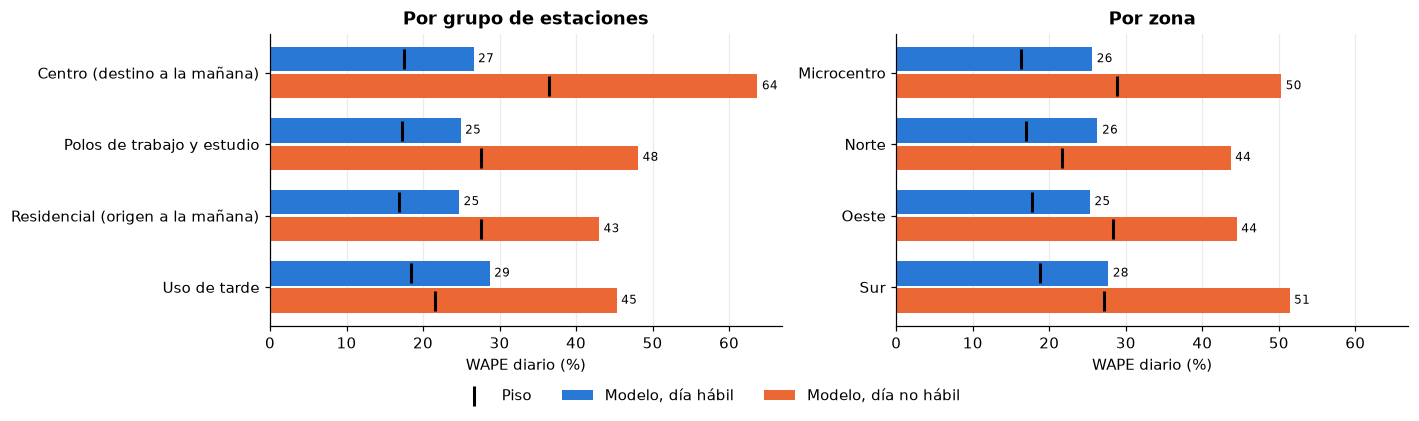

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharex=True)
for ax, columna, titulo in [(axes[0], "nombre_grupo", "Por grupo de estaciones"), (axes[1], "zona", "Por zona")]:
    t = por(columna, "tipo_dia").reset_index()
    etiquetas = t[columna].unique()[::-1]
    for desplazamiento, tipo, color in [(0.19, "hábil", BLUE), (-0.19, "no hábil", ORANGE)]:
        fila = t[t.tipo_dia == tipo].set_index(columna).loc[etiquetas]
        y = np.arange(len(etiquetas)) + desplazamiento
        ax.barh(y, fila["WAPE modelo %"], height=0.34, color=color, label=f"Modelo, día {tipo}")
        ax.scatter(fila["piso %"], y, marker="|", s=170, color="black", lw=2, zorder=3, label="Piso" if tipo == "no hábil" else None)
        for yy, v in zip(y, fila["WAPE modelo %"]):
            ax.text(v + 0.6, yy, f"{v:.0f}", va="center", fontsize=8)
    ax.set_yticks(np.arange(len(etiquetas)), etiquetas)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("WAPE diario (%)")
    ax.set_title(titulo)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, ncols=3, loc="lower center", bbox_to_anchor=(0.5, -0.07))
plt.tight_layout()
plt.show()

In [12]:
por("nombre_grupo", "zona")

estaciones  retiros por día y estación  WAPE modelo %  WAPE media histórica %  piso %  sobre el piso (pp)  sesgo modelo %
nombre_grupo                     zona                                                                                                                                  
Centro (destino a la mañana)     Microcentro        29.0                        15.7           30.4                    60.7    19.3                11.1             3.0
                                 Norte               2.0                         5.0           53.0                    75.9    35.7                17.3             7.0
                                 Oeste               1.0                        17.9           23.8                    28.0    17.7                 6.1            -3.0
Polos de trabajo y estudio       Microcentro        15.0                        17.6           27.4                    67.2    18.1                 9.3             1.7
                                 Norte              21.0                        17.8           28.8                    43.4    17.8                11.0            -1.1
                                 Oeste              30.0                        14.5           27.6                    38.7    19.7                 7.9            -0.8
                                 Sur                 7.0                        12.7           33.3                    75.5    20.7                12.6             0.5
Residencial (origen a la mañana) Microcentro        25.0                        20.5           26.9                    60.2    16.8                10.2             1.7
                                 Norte              41.0                        15.8           28.4                    52.7    19.2                 9.2             1.6
                                 Oeste             105.0                        16.4           26.8                    45.0    18.6                 8.2            -0.0
                                 Sur                14.0                        16.0           29.9                    64.0    18.9                11.0             3.2
Uso de tarde                     Microcentro         4.0                        19.4           36.6                    76.5    17.1                19.5             0.8
                                 Norte              30.0                        20.5           31.9                    60.7    16.5                15.4            -0.6
                                 Oeste              54.0                        12.4           32.1                    46.8    21.2                10.9            -0.9
                                 Sur                16.0                        11.6           32.6                    55.0    21.0                11.6            -2.2

In [13]:
franjas = (test.assign(franja=pd.cut(test.hora, [-1, 5, 9, 15, 19, 23], labels=["0–5", "6–9", "10–15", "16–19", "20–23"]))
               .query("dia_habil == 1")
               .groupby(["station_id", "fecha", "franja"], observed=True)[["retiros", "pred_retiros", "arribos", "pred_arribos"]].sum()
               .reset_index().join(estaciones.nombre_grupo, on="station_id"))
pd.concat({objetivo: franjas.groupby(["nombre_grupo", "franja"], observed=True)[franjas.columns.tolist()]
                            .apply(lambda d: wape(d[objetivo], d[f"pred_{objetivo}"])).unstack()
           for objetivo in ["retiros", "arribos"]}, names=["WAPE % por franja, días hábiles"]).round(1)

franja                                                              0–5   6–9  10–15  16–19  20–23
WAPE % por franja, días hábiles nombre_grupo                                                      
retiros                         Centro (destino a la mañana)      116.3  55.5   34.0   48.4   82.8
                                Polos de trabajo y estudio        102.4  56.4   35.1   39.6   64.3
                                Residencial (origen a la mañana)   85.0  52.5   37.0   39.1   54.9
                                Uso de tarde                      104.5  60.6   42.0   43.6   60.2
arribos                         Centro (destino a la mañana)      101.5  42.6   35.5   50.1   84.8
                                Polos de trabajo y estudio         99.3  47.1   36.4   40.3   62.3
                                Residencial (origen a la mañana)   81.6  55.8   35.4   37.6   51.0
                                Uso de tarde                      106.0  62.9   40.8   40.4   60.2

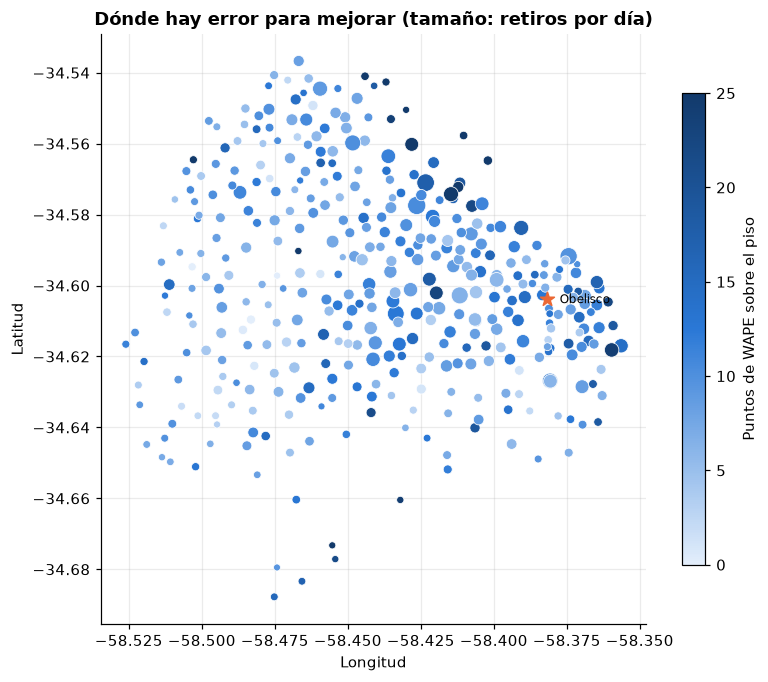

382 estaciones con 5 o más retiros por día. Las de más error sobre el piso, con más de 15:


,nombre,zona,nombre_grupo,retiros por día y estación,WAPE modelo %,piso %,sobre el piso (pp)
station_id,,,,,,,
210,335 - General Urquiza,Norte,Uso de tarde,19.8,51.4,17.5,34.0
515,294 - PLAZOLETA RÍO DE LA PLATA,Norte,Uso de tarde,39.2,42.8,12.4,30.4
379,390 - De Los Ombues,Norte,Uso de tarde,33.0,41.7,13.6,28.0
152,152 - JULIETA LANTERI,Sur,Polos de trabajo y estudio,36.0,36.8,12.7,24.0
161,161 - Humahuaca,Oeste,Uso de tarde,32.3,35.9,13.2,22.7
570,030 - GIRALT,Microcentro,Uso de tarde,15.1,42.3,19.9,22.4
156,156 - Plaza Alemania,Norte,Polos de trabajo y estudio,26.3,36.9,15.0,21.9
21,021 - Parque Patricios,Sur,Uso de tarde,15.8,38.2,19.0,19.2
177,177 -PLANETARIO,Norte,Uso de tarde,22.3,35.6,16.5,19.1


In [14]:
estacion = diario.groupby("station_id")[diario.columns.tolist()].apply(resumen).join(estaciones[["nombre", "lat", "lon", "zona", "nombre_grupo"]])
estacion["sobre el piso (pp)"] = estacion["WAPE modelo %"] - estacion["piso %"]
con_volumen = estacion[estacion["retiros por día y estación"] >= 5]

fig, ax = plt.subplots(figsize=(7.5, 6.3))
puntos = ax.scatter(con_volumen.lon, con_volumen.lat, c=con_volumen["sobre el piso (pp)"], cmap=AZULES, vmin=0, vmax=25,
                    s=10 + 2.2 * con_volumen["retiros por día y estación"], edgecolor="white", lw=0.5)
ax.scatter(*OBELISCO[::-1], marker="*", s=90, color=ORANGE, zorder=3)
ax.annotate("Obelisco", OBELISCO[::-1], xytext=(8, -3), textcoords="offset points", fontsize=8)
ax.set_aspect(1 / np.cos(np.radians(OBELISCO[0])))
fig.colorbar(puntos, label="Puntos de WAPE sobre el piso", shrink=0.8)
ax.set_title("Dónde hay error para mejorar (tamaño: retiros por día)")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
plt.tight_layout()
plt.show()
print(f"{len(con_volumen)} estaciones con 5 o más retiros por día. Las de más error sobre el piso, con más de 15:")
(con_volumen[con_volumen["retiros por día y estación"] > 15].sort_values("sobre el piso (pp)", ascending=False)
    [["nombre", "zona", "nombre_grupo", "retiros por día y estación", "WAPE modelo %", "piso %", "sobre el piso (pp)"]].head(10).round(1))

**Interpretación de lo obtenido.**

- **Por zona el modelo rinde parejo:** 28,2 % (Oeste), 28,8 % (Microcentro), 29,9 % (Norte) y 31,7 % (Sur). Las del Sur tienen menos viajes y, por lo tanto, un piso más alto. Sobre el piso, quedan todas entre 9 y 12 puntos. **No falla más en la periferia residencial que en el microcentro.**
- **Por grupo, lo más fácil es lo residencial y lo más difícil el uso de tarde:** 27,4 % contra 32,3 %, con pisos casi iguales (18,4 y 19,1 %). El viaje al trabajo es regular. El uso de tarde depende del clima, del día y de eventos.
- **La diferencia grande es el tipo de día:** 25,8 % en días hábiles y **45,8 % en no hábiles**. Una parte es volumen (piso de 26 %), pero sobre el piso quedan 20 puntos contra 8,5. Los peores son **Centro** en días no hábiles (64 %, aunque son pocos viajes) y, por cantidad de viajes, **Uso de tarde**.
- **El mapa muestra dónde mejorar:** el error sobre el piso se concentra en la **costa y los parques** (Plazoleta Río de la Plata, De los Ombúes, Julieta Lanteri, Plaza Alemania, Planetario). General Urquiza y Humahuaca no responden a ese patrón y no se verificó la causa.
- **Le gana a la media histórica en todos los grupos y zonas.** La ventaja es mayor en Microcentro y Sur (62,7 % de la media histórica contra 28,8 y 31,7 %).
- **Por franja**, a la mañana de los días hábiles se predicen mejor los **arribos** en el Centro (43 %) que los retiros (56 %): es el sentido del viaje al trabajo. Para el rebalanceo conviene confiar más en la lista de **descargar** del centro que en la de abastecer, lo mismo que mostró el notebook 04 (precisión de 50 % contra 38 %).

**Qué cambia en el uso:** los planes de días hábiles son confiables en toda la ciudad. Los fines de semana, los feriados y las estaciones recreativas necesitan más margen o revisión de una persona.

## 3. Interpretación del boosting con SHAP

**Devolución:** *"para el HistGradientBoostingRegressor sería sumamente valioso incorporar valores SHAP (...) visualizar interacciones complejas no lineales (por ejemplo, cómo el impacto de la temperatura o la lluvia varía según la franja horaria o el nivel base de la estación)"*.

Los valores SHAP reparten cada predicción entre sus variables. El modelo tiene pérdida de Poisson, así que predice en **escala logarítmica**: la suma de los valores SHAP más el valor base es el logaritmo de los viajes esperados. Por eso cada valor se lee como un **multiplicador**: un SHAP de −0,29 multiplica la predicción por $e^{-0{,}29} = 0{,}75$, es decir, la baja un 25 %.

**Datos:** para la importancia global se usa una muestra del test. El test es sólo invierno, así que para la lluvia y la temperatura se usa el **último año** (septiembre de 2025 a agosto de 2026). Ese año incluye meses de entrenamiento, pero acá no se mide el error: se explica qué aprendió el modelo.

In [15]:
explicador = shap.TreeExplainer(modelo_retiros)


def explicar(filas):
    valores = explicador.shap_values(filas[VARIABLES])
    logaritmo = np.log(modelo_retiros.predict(filas[VARIABLES]))
    assert np.allclose(explicador.expected_value + valores.sum(axis=1), logaritmo, atol=1e-6)  # suman la predicción
    return pd.DataFrame(valores, columns=VARIABLES, index=filas.index)


inicio = time.perf_counter()
muestra = test.sample(8_000, random_state=SEMILLA)
shap_test = explicar(muestra)
print(f"{len(muestra):,} filas explicadas en {time.perf_counter() - inicio:.0f} s. Los valores SHAP suman el logaritmo de la predicción en todas.")

8,000 filas explicadas en 34 s. Los valores SHAP suman el logaritmo de la predicción en todas.


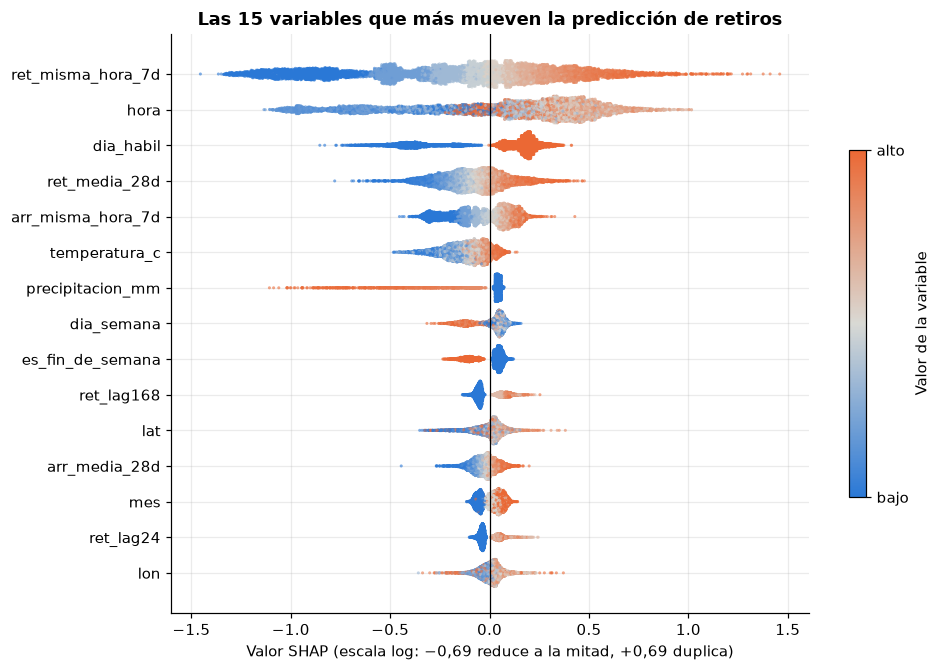

,ret_misma_hora_7d,hora,dia_habil,ret_media_28d,arr_misma_hora_7d,temperatura_c,precipitacion_mm,dia_semana,es_fin_de_semana,ret_lag168
media de |SHAP|,0.44,0.394,0.24,0.144,0.125,0.124,0.074,0.068,0.064,0.063


In [16]:
importancia = shap_test.abs().mean().sort_values(ascending=False)
principales = importancia.index[:15][::-1]
rng = np.random.default_rng(SEMILLA)
MAPA_VALOR = LinearSegmentedColormap.from_list("valor", [BLUE, "#d9d9d4", ORANGE])

fig, ax = plt.subplots(figsize=(9, 6.2))
for y, variable in enumerate(principales):
    x = shap_test[variable].to_numpy()
    rango = muestra[variable].rank(pct=True).to_numpy()
    # dispersión vertical según la densidad, para que se vea la forma de la distribución
    cuentas, bordes = np.histogram(x, bins=80)
    densidad = cuentas[np.clip(np.digitize(x, bordes) - 1, 0, 79)] / cuentas.max()
    ax.scatter(x, y + rng.uniform(-0.38, 0.38, len(x)) * densidad, c=rango, cmap=MAPA_VALOR, s=4, alpha=0.6, lw=0, rasterized=True)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(principales)), principales)
ax.set_xlabel("Valor SHAP (escala log: −0,69 reduce a la mitad, +0,69 duplica)")
ax.set_title("Las 15 variables que más mueven la predicción de retiros")
barra = fig.colorbar(plt.cm.ScalarMappable(cmap=MAPA_VALOR), ax=ax, ticks=[0, 1], shrink=0.6, label="Valor de la variable")
barra.ax.set_yticklabels(["bajo", "alto"])
plt.tight_layout()
plt.show()
importancia.head(10).round(3).to_frame("media de |SHAP|").T

### 3.1 Lluvia × hora

El efecto de la lluvia es la suma de los valores SHAP de `precipitacion_mm` y `llueve`. Se muestrean horas de **día hábil entre las 6 y las 22 h** con y sin lluvia, y se compara cada intensidad contra las horas **sin lluvia de la misma hora del día**.

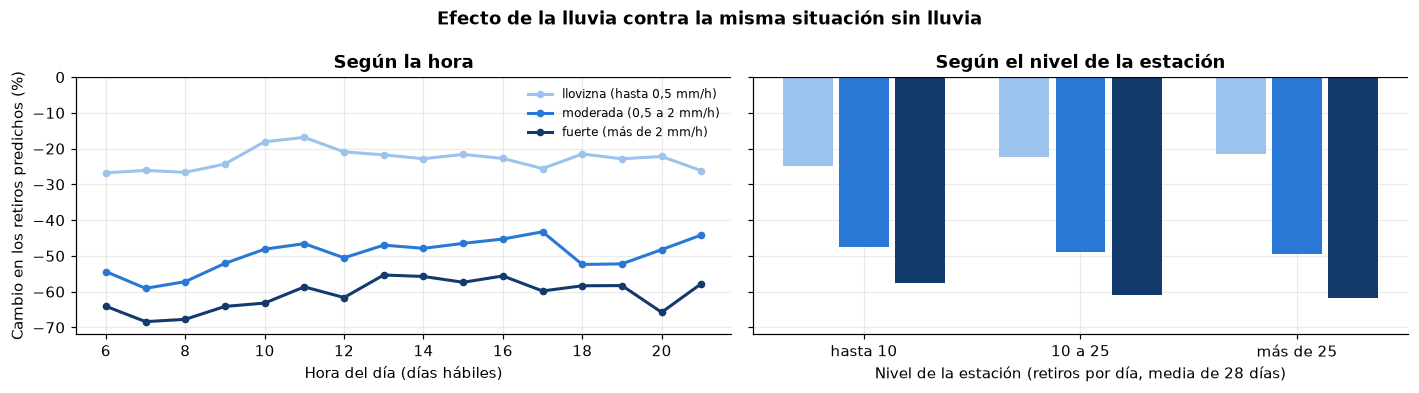

Calculado en 58 s. Horas por intensidad en el año (días hábiles, 6 a 21 h): {'sin lluvia': 3468, 'llovizna (hasta 0,5 mm/h)': 241, 'moderada (0,5 a 2 mm/h)': 115, 'fuerte (más de 2 mm/h)': 64}


intensidad                              llovizna (hasta 0,5 mm/h)  moderada (0,5 a 2 mm/h)  fuerte (más de 2 mm/h)
hora  6–9                                                   -26.0                    -56.0                   -66.0
      10–13                                                 -20.0                    -48.0                   -60.0
      14–17                                                 -23.0                    -46.0                   -57.0
      18–21                                                 -23.0                    -50.0                   -59.0
nivel hasta 10                                              -25.0                    -47.0                   -57.0
      10 a 25                                               -22.0                    -49.0                   -61.0
      más de 25                                             -22.0                    -50.0                   -62.0
grupo Centro (destino a la mañana)                          -23.0                    -48.0                   -61.0
      Polos de trabajo y estudio                            -22.0                    -49.0                   -60.0
      Residencial (origen a la mañana)                      -22.0                    -49.0                   -61.0
      Uso de tarde                                          -22.0                    -48.0                   -60.0

In [17]:
inicio = time.perf_counter()
ultimo_anio = variables(pd.Timestamp("2025-09-01"), TEST_HASTA)
INTENSIDADES = ["sin lluvia", "llovizna (hasta 0,5 mm/h)", "moderada (0,5 a 2 mm/h)", "fuerte (más de 2 mm/h)"]
ultimo_anio["intensidad"] = pd.cut(ultimo_anio.precipitacion_mm, [-1, 0, 0.5, 2, np.inf], labels=INTENSIDADES)
diurnas = ultimo_anio[ultimo_anio.hora.between(6, 21)]

muestra_lluvia = (diurnas[diurnas.dia_habil == 1].groupby("intensidad", observed=True).sample(3_000, random_state=SEMILLA))
shap_lluvia = explicar(muestra_lluvia)
efecto = muestra_lluvia.assign(efecto=shap_lluvia.precipitacion_mm + shap_lluvia.llueve)


def contra_seco(datos, clave):
    t = datos.groupby([clave, "intensidad"], observed=True).efecto.mean().unstack()
    return 100 * (np.exp(t.sub(t["sin lluvia"], axis=0)) - 1)


efecto["bloque"] = pd.cut(efecto.hora, [5, 9, 13, 17, 21], labels=["6–9", "10–13", "14–17", "18–21"])
efecto["nivel"] = pd.cut(24 * efecto.ret_media_28d, [-1, 10, 25, np.inf], labels=["hasta 10", "10 a 25", "más de 25"])
efecto = efecto.join(estaciones.nombre_grupo, on="station_id")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
por_hora, por_nivel = contra_seco(efecto, "hora"), contra_seco(efecto, "nivel")
for intensidad, color in zip(INTENSIDADES[1:], ["#9cc3ee", BLUE, "#123a6b"]):
    axes[0].plot(por_hora.index, por_hora[intensidad], color=color, lw=2, marker="o", ms=4, label=intensidad)
ancho = 0.26
for i, (intensidad, color) in enumerate(zip(INTENSIDADES[1:], ["#9cc3ee", BLUE, "#123a6b"])):
    axes[1].bar(np.arange(len(por_nivel)) + (i - 1) * ancho, por_nivel[intensidad], width=ancho - 0.03, color=color)
axes[0].set_xlabel("Hora del día (días hábiles)")
axes[0].set_ylabel("Cambio en los retiros predichos (%)")
axes[0].set_title("Según la hora")
axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xticks(np.arange(len(por_nivel)), por_nivel.index)
axes[1].set_xlabel("Nivel de la estación (retiros por día, media de 28 días)")
axes[1].set_title("Según el nivel de la estación")
for ax in axes:
    ax.axhline(0, color="black", lw=0.8)
fig.suptitle("Efecto de la lluvia contra la misma situación sin lluvia", fontweight="bold")
plt.tight_layout()
plt.show()
print(f"Calculado en {time.perf_counter() - inicio:.0f} s. Horas por intensidad en el año (días hábiles, 6 a 21 h):",
      diurnas[diurnas.dia_habil == 1].groupby("intensidad", observed=True).ts.nunique().to_dict())
pd.concat([contra_seco(efecto, "bloque"), contra_seco(efecto, "nivel"), contra_seco(efecto, "nombre_grupo")],
          keys=["hora", "nivel", "grupo"]).drop(columns="sin lluvia").round(0)

### 3.2 Temperatura × nivel de la estación y tipo de día

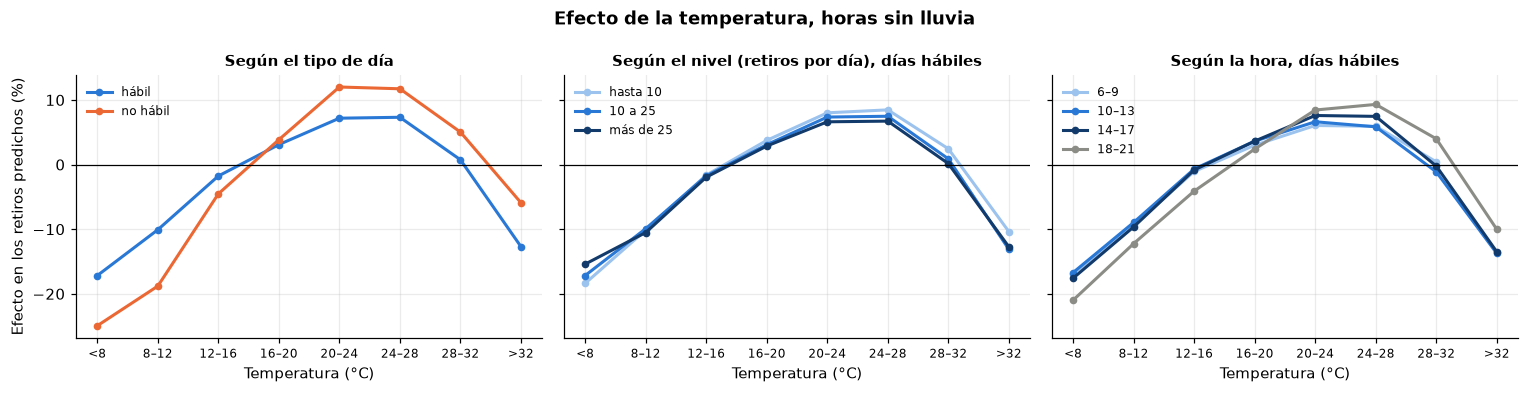

día             nivel                    hora                  
      hábil no hábil hasta 10 10 a 25 más de 25   6–9 10–13 14–17 18–21
tramo                                                                  
<8    -17.0    -25.0    -18.0   -17.0     -15.0 -17.0 -17.0 -18.0 -21.0
8–12  -10.0    -19.0    -10.0   -10.0     -11.0  -9.0  -9.0 -10.0 -12.0
12–16  -2.0     -5.0     -2.0    -2.0      -2.0  -1.0  -1.0  -1.0  -4.0
16–20   3.0      4.0      4.0     3.0       3.0   3.0   4.0   4.0   2.0
20–24   7.0     12.0      8.0     7.0       7.0   6.0   7.0   8.0   8.0
24–28   7.0     12.0      8.0     7.0       7.0   6.0   6.0   7.0   9.0
28–32   1.0      5.0      2.0     1.0       0.0   0.0  -1.0  -0.0   4.0
>32   -13.0     -6.0    -10.0   -13.0     -13.0   NaN -14.0 -14.0 -10.0

In [18]:
TRAMOS = [-np.inf, 8, 12, 16, 20, 24, 28, 32, np.inf]
NOMBRES_TRAMOS = ["<8", "8–12", "12–16", "16–20", "20–24", "24–28", "28–32", ">32"]
diurnas = diurnas.assign(tramo=pd.cut(diurnas.temperatura_c, TRAMOS, labels=NOMBRES_TRAMOS))
muestra_temp = diurnas[diurnas.precipitacion_mm == 0].groupby(["tramo", "dia_habil"], observed=True).sample(900, random_state=SEMILLA)
shap_temp = explicar(muestra_temp)
temp = muestra_temp.assign(efecto=shap_temp.temperatura_c)
temp["nivel"] = pd.cut(24 * temp.ret_media_28d, [-1, 10, 25, np.inf], labels=["hasta 10", "10 a 25", "más de 25"])
temp["bloque"] = pd.cut(temp.hora, [5, 9, 13, 17, 21], labels=["6–9", "10–13", "14–17", "18–21"])
temp = temp.join(estaciones.nombre_grupo, on="station_id")


def porcentaje(datos, clave):
    return 100 * (np.exp(datos.groupby(["tramo", clave], observed=True).efecto.mean().unstack()) - 1)


fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
habiles = temp[temp.dia_habil == 1]
paneles = [(axes[0], porcentaje(temp, "dia_habil").rename(columns={0: "no hábil", 1: "hábil"})[["hábil", "no hábil"]], [BLUE, ORANGE], "Según el tipo de día"),
           (axes[1], porcentaje(habiles, "nivel"), ["#9cc3ee", BLUE, "#123a6b"], "Según el nivel (retiros por día), días hábiles"),
           (axes[2], porcentaje(habiles, "bloque"), ["#9cc3ee", BLUE, "#123a6b", GRAY], "Según la hora, días hábiles")]
for ax, t, colores, titulo in paneles:
    for columna, color in zip(t.columns, colores):
        ax.plot(range(len(t)), t[columna], color=color, lw=2, marker="o", ms=4, label=columna)
    ax.set_xticks(range(len(t)), t.index, fontsize=8)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Temperatura (°C)")
    ax.set_title(titulo, fontsize=10)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Efecto en los retiros predichos (%)")
fig.suptitle("Efecto de la temperatura, horas sin lluvia", fontweight="bold")
plt.tight_layout()
plt.show()
display(pd.concat([t for _, t, _, _ in paneles], axis=1, keys=["día", "nivel", "hora"]).round(0))

### 3.3 ¿Por qué el modelo predice lo que predice? Un ejemplo

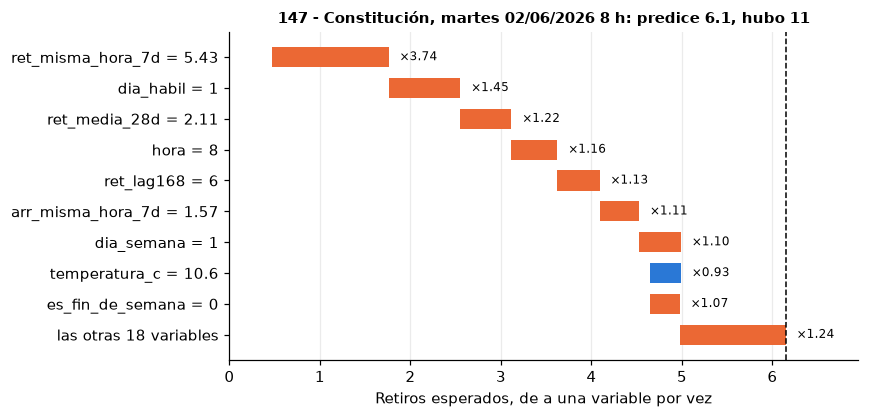

In [19]:
ejemplo = test[(test.station_id == 175) & (test.ts == "2026-06-02 08:00")]  # 147 - Constitución, la primera a abastecer
valores = explicar(ejemplo).iloc[0]
orden = valores.abs().sort_values(ascending=False).index[:9]
cascada = pd.concat([valores[orden], pd.Series({"las otras 18 variables": valores.drop(orden).sum()})])
etiquetas = [f"{v} = {ejemplo[v].iloc[0]:.2f}".rstrip("0").rstrip(".") if v in VARIABLES else v for v in cascada.index]

fig, ax = plt.subplots(figsize=(8, 3.9))
acumulado = float(np.ravel(explicador.expected_value)[0])
for y, (valor, etiqueta) in enumerate(zip(cascada, etiquetas)):
    desde, hasta = np.exp(acumulado), np.exp(acumulado + valor)
    ax.barh(y, hasta - desde, left=desde, color=ORANGE if valor > 0 else BLUE, height=0.65)
    ax.text(max(desde, hasta) + 0.12, y, f"×{np.exp(valor):.2f}", va="center", fontsize=8)
    acumulado += valor
ax.axvline(np.exp(acumulado), color="black", lw=1, ls="--")
ax.set_yticks(range(len(cascada)), etiquetas)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlim(0, ax.get_xlim()[1] * 1.08)
ax.set_xlabel("Retiros esperados, de a una variable por vez")
ax.set_title(f"147 - Constitución, martes 02/06/2026 8 h: predice {np.exp(acumulado):.1f}, hubo {int(ejemplo.retiros.iloc[0])}", fontsize=10)
plt.tight_layout()
plt.show()

**Interpretación de lo obtenido.**

- **Importancia global:** manda el promedio de la **misma hora en la última semana**, después la **hora** y el **tipo de día**. El orden es muy parecido al de la permutación (notebook 04, sección 10.4). SHAP agrega la **dirección** y la forma: la lluvia casi siempre vale 0, pero cuando llueve es de las que más bajan la predicción (la cola de `precipitacion_mm` llega a dividirla por 3).
- **Lluvia × hora:** el efecto crece con la intensidad: −22 % con llovizna, −49 % con lluvia moderada y −60 % con lluvia fuerte (la regresión de Poisson, con una sola variable sí/no, daba −25 %). Es **más fuerte a la mañana** (6 a 9 h: −26, −56 y −66 %) que entre las 10 y las 13 (−20, −48 y −60 %). Una explicación posible es que a la mañana hay alternativas de transporte para el viaje al trabajo, pero los datos no lo prueban.
- **Lluvia × nivel:** el efecto relativo es **casi el mismo** en estaciones chicas y grandes (−57 a −62 % con lluvia fuerte) y en los cuatro grupos. En viajes absolutos, las estaciones grandes pierden más.
- **Temperatura:** forma de **U invertida**, con el máximo entre 20 y 28 °C y una caída por encima de los 32 °C (−13 % en días hábiles). Un modelo lineal no puede verla.
- **Temperatura × tipo de día:** en los días **no hábiles** la temperatura pesa más: −25 % con menos de 8 °C (−17 % en hábiles) y +12 % entre 20 y 28 °C (+7 %). El viaje recreativo se posterga y el laboral no. A la **tarde-noche** (18 a 21 h) el frío también pesa más que de día.
- **Temperatura × nivel:** no hay interacción visible: las tres curvas son casi iguales.
- **El ejemplo:** para Constitución a las 8, la historia reciente de esa hora multiplica la predicción por 3,7, y el día hábil por 1,45. El modelo predijo 6,1 y hubo 11. Ese día la demanda real fue más alta que la de la última semana (5,4 de promedio), que es lo que más mira el modelo.

**Límites:** SHAP explica **el modelo**, no la causa. Con variables correlacionadas reparte el efecto entre ellas: la temperatura compite con `mes` y con los rezagos, que ya traen la temporada, así que su efecto es **adicional** al nivel de los últimos días. Hubo sólo 64 horas hábiles de lluvia fuerte en el año: esa curva es la menos segura.

## 4. Conclusiones

1. **El modelo sirve para operar y le gana a la media histórica donde se esperaba:** con las mismas bicis deja un 4,8 % menos de alertas y un 7,8 % menos de horas-estación en alerta (100 bicis por franja). La ventaja es consistente pero moderada: **el salto grande es pasar de no mover a mover con criterio** (−52 % de alertas), y la mayor parte se logra también con reglas simples.
2. **El pronóstico vale más cuanto más se puede mover.** Con poco presupuesto alcanza con llenar lo que ya está vacío. Con 200 bicis por franja el modelo ya deja menos alertas que equilibrar el stock (3,0 %, con el plan que minimiza el tiempo), y con 400 la diferencia es clara en alertas, horas y usuarios.
3. **El error no es un problema de zona sino de tipo de viaje:** lo laboral se predice bien en toda la ciudad, y lo recreativo y los fines de semana, no.
4. **El modelo aprendió relaciones con sentido:** la lluvia según su intensidad y la hora, y la temperatura con un óptimo, más marcada los fines de semana.

**Próximos pasos que surgen de este análisis:** un target propio para el rebalanceo (el flujo neto de la franja, notebook 04), variables para la demanda recreativa (distancia a parques y a la costa, eventos), y simular con tiempos de traslado y ruteo de camiones.